# NB_BioAcoustics_2 — Feature Extraction
**IRA AI Platform — Plant Bioacoustics Module**

**Purpose:** Extract MFCC features and basic acoustic features from each WAV file.
Build a feature matrix ready for classification in NB3.

**Prerequisite:** Run NB_BioAcoustics_1 first → generates `bioacoustics_master_index.csv`

**What features we extract and why:**

| Feature | What it captures | Why it matters |
|---------|-----------------|----------------|
| MFCC (13 coefficients) | Spectral shape (timbre) of the sound | Different plants have different xylem tube widths → different peak frequencies |
| Peak frequency | Dominant frequency in the pop | Core discriminator between tomato/tobacco (paper: ~50 vs ~55 kHz) |
| Peak amplitude | How loud the pop was | Relates to stress severity |
| Spectral centroid | Center of mass of spectrum | Summary of where energy lives |
| Spectral bandwidth | Spread of energy around centroid | Narrowband vs broadband pop |
| RMS energy | Average signal power | Overall loudness |
| Zero-crossing rate | Oscillation speed in time domain | Texture of the burst |

**Note on scattering networks:** The paper's best results used scattering networks (SN).
Implementing SN from scratch requires the `kymatio` library. We implement MFCC here
(which also achieved significant accuracy). SN will be added in NB3 if kymatio is available.

In [29]:
# ── Imports ──────────────────────────────────────────────────────────────────
import os
import wave
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.signal import spectrogram as scipy_spectrogram
from scipy.fft import rfft, rfftfreq
from tqdm import tqdm

# Check if librosa is available (used for MFCC)
try:
    import librosa
    import librosa.display
    LIBROSA_AVAILABLE = True
    print("librosa available — will use for MFCC.")
except ImportError:
    LIBROSA_AVAILABLE = False
    print("librosa NOT found. Install with: pip install librosa")
    print("Falling back to scipy-based MFCC approximation.")

print("Libraries loaded.")

librosa available — will use for MFCC.
Libraries loaded.


In [30]:
# ── Configuration ─────────────────────────────────────────────────────────────
DATA_ROOT = Path(r"C:/Users/alato/Downloads/files/PlantSounds")
INDEX_PATH = Path("C:/Users/alato/Downloads/files/bioacoustics_master_index.csv")

CLASS_FOLDERS = {
    "Tomato_Dry":       "Tomato Dry",
    "Tomato_Cut":       "Tomato Cut",
    "Tobacco_Dry":      "Tobacco Dry",
    "Tobacco_Cut":      "Tobacco Cut",
    "Greenhouse_Noise": "Greenhouse Noises",
    "Empty_Pot":        "Empty Pot",
}

SR          = 500_000   # 500 kHz
N_MFCC      = 13        # number of MFCC coefficients (paper used MFCC + scattering)
FREQ_LOW    = 20_000    # 20 kHz — high-pass filter cutoff (below this = filtered in paper)
FREQ_HIGH   = 150_000   # 150 kHz — upper limit of microphone sensitivity

# Classes to use for ML (exclude Empty_Pot for main experiments)
ML_CLASSES = ["Tomato_Dry", "Tomato_Cut", "Tobacco_Dry",
              "Tobacco_Cut", "Greenhouse_Noise"]

print("Configuration OK.")

Configuration OK.


## 1. Load master index from NB1

In [31]:
if not INDEX_PATH.exists():
    raise FileNotFoundError(
        f"Master index not found at {INDEX_PATH}.\n"
        "Please run NB_BioAcoustics_1_DataAudit.ipynb first."
    )

index = pd.read_csv(INDEX_PATH)
# Keep only non-silent, non-anomalous files
index_clean = index[
    (index["is_silent"] == False) &
    (index["anomalies"] == "none")
].copy()

print(f"Total files in index  : {len(index)}")
print(f"After quality filter  : {len(index_clean)}")
print(f"Dropped               : {len(index) - len(index_clean)}")
print("\nCounts per class:")
print(index_clean["class"].value_counts().to_string())

Total files in index  : 5477
After quality filter  : 5477
Dropped               : 0

Counts per class:
class
Tomato_Dry          1622
Greenhouse_Noise    1378
Empty_Pot           1036
Tomato_Cut           660
Tobacco_Cut          506
Tobacco_Dry          275


## 2. Feature extraction functions

In [32]:
def load_wav(filepath: str) -> np.ndarray:
    """Load a 16-bit WAV file, return float32 array."""
    with wave.open(str(filepath), "r") as w:
        raw = w.readframes(w.getnframes())
    return np.frombuffer(raw, dtype=np.int16).astype(np.float32)


def extract_basic_features(signal: np.ndarray, sr: int) -> dict:
    """
    Basic acoustic features:
    - peak_amplitude  : max |x|
    - rms_energy      : root mean square
    - peak_freq_kHz   : frequency with maximum power
    - spectral_centroid_kHz
    - spectral_bandwidth_kHz
    - zero_crossing_rate
    - energy_20_70    : fraction of energy in 20–70 kHz
    - energy_70_150   : fraction of energy in 70–150 kHz
    """
    N    = len(signal)
    sig  = signal * np.hanning(N)  # window before FFT

    # FFT
    fft_mag = np.abs(rfft(sig))
    freqs   = rfftfreq(N, 1 / sr)  # Hz

    # Restrict to 20–150 kHz (paper's range)
    mask = (freqs >= FREQ_LOW) & (freqs <= FREQ_HIGH)
    fft_band  = fft_mag[mask]
    freq_band = freqs[mask]
    total_power = fft_mag.sum() + 1e-9

    peak_freq   = freq_band[np.argmax(fft_band)] / 1000 if len(fft_band) > 0 else 0

    # Spectral centroid and bandwidth
    if fft_band.sum() > 0:
        weights  = fft_band / fft_band.sum()
        centroid = np.sum(freq_band * weights) / 1000  # kHz
        bandwidth= np.sqrt(np.sum(((freq_band/1000 - centroid)**2) * weights))
    else:
        centroid, bandwidth = 0, 0

    # Zero-crossing rate
    zcr = np.mean(np.diff(np.sign(signal)) != 0)

    # Band energy ratios
    mask_lo  = (freqs >= 20_000)  & (freqs < 70_000)
    mask_hi  = (freqs >= 70_000)  & (freqs <= 150_000)
    e_lo     = fft_mag[mask_lo].sum() / total_power
    e_hi     = fft_mag[mask_hi].sum() / total_power

    return {
        "peak_amplitude":          float(np.max(np.abs(signal))),
        "rms_energy":              float(np.sqrt(np.mean(signal**2))),
        "peak_freq_kHz":           float(peak_freq),
        "spectral_centroid_kHz":   float(centroid),
        "spectral_bandwidth_kHz":  float(bandwidth),
        "zero_crossing_rate":      float(zcr),
        "energy_ratio_20_70kHz":   float(e_lo),
        "energy_ratio_70_150kHz":  float(e_hi),
    }


def extract_mfcc_features(signal: np.ndarray, sr: int,
                           n_mfcc: int = 13) -> dict:
    """
    MFCC features. Returns mean and std of each coefficient over time.
    Uses librosa if available, otherwise falls back to a scipy approximation.
    """
    # Normalize signal
    sig_norm = signal / (np.max(np.abs(signal)) + 1e-9)

    if LIBROSA_AVAILABLE:
        # librosa expects float32, sr in Hz
        # n_fft should be ≤ len(signal); use 256 for 1001-sample signal
        mfccs = librosa.feature.mfcc(
            y       = sig_norm,
            sr      = sr,
            n_mfcc  = n_mfcc,
            n_fft   = 256,
            hop_length = 64,
            fmin    = FREQ_LOW,
            fmax    = FREQ_HIGH,
        )
        mfcc_mean = mfccs.mean(axis=1)  # shape (n_mfcc,)
        mfcc_std  = mfccs.std(axis=1)
    else:
        # Simple fallback: use FFT bands as pseudo-MFCC
        fft_mag = np.abs(rfft(sig_norm * np.hanning(len(sig_norm))))
        freqs   = rfftfreq(len(sig_norm), 1/sr)
        # Split 20–150 kHz into n_mfcc equal bands
        edges   = np.linspace(FREQ_LOW, FREQ_HIGH, n_mfcc + 1)
        mfcc_mean = np.array([
            fft_mag[(freqs >= edges[i]) & (freqs < edges[i+1])].mean()
            for i in range(n_mfcc)
        ])
        mfcc_std = np.zeros(n_mfcc)

    features = {}
    for i in range(n_mfcc):
        features[f"mfcc_{i+1:02d}_mean"] = float(mfcc_mean[i])
        features[f"mfcc_{i+1:02d}_std"]  = float(mfcc_std[i])
    return features


def extract_all_features(filepath: str) -> dict:
    """Load a WAV file and return all features as a flat dict."""
    signal  = load_wav(filepath)
    basic   = extract_basic_features(signal, SR)
    mfcc    = extract_mfcc_features(signal, SR, N_MFCC)
    return {**basic, **mfcc}


print("Feature extraction functions defined.")
print(f"Total features per file: {8 + N_MFCC * 2}  "
      f"(8 basic + {N_MFCC} MFCC mean + {N_MFCC} MFCC std)")

Feature extraction functions defined.
Total features per file: 34  (8 basic + 13 MFCC mean + 13 MFCC std)


## 3. Quick test on the 4 uploaded files

In [33]:
# Test on a single file first
# If you have the full dataset, change this path
test_files = [
    DATA_ROOT / "Tomato Dry" / "id_8_sound_4.wav",
    DATA_ROOT / "Tomato Dry" / "id_8_sound_5.wav",
]

for fpath in test_files:
    if fpath.exists():
        feats = extract_all_features(str(fpath))
        print(f"\n{fpath.name}:")
        for k, v in feats.items():
            if "mfcc" not in k or "01" in k or "13" in k:
                print(f"  {k:35s}: {v:.4f}")
        print(f"  ... ({len(feats)} features total)")
    else:
        print(f"Not found: {fpath} — run with full dataset")


id_8_sound_4.wav:
  peak_amplitude                     : 3875.0000
  rms_energy                         : 387.1079
  peak_freq_kHz                      : 37.4625
  spectral_centroid_kHz              : 73.8661
  spectral_bandwidth_kHz             : 34.2024
  zero_crossing_rate                 : 0.5670
  energy_ratio_20_70kHz              : 0.3595
  energy_ratio_70_150kHz             : 0.3370
  mfcc_01_mean                       : -567.5334
  mfcc_01_std                        : 35.1291
  mfcc_13_mean                       : 5.2982
  mfcc_13_std                        : 8.4400
  ... (34 features total)

id_8_sound_5.wav:
  peak_amplitude                     : 9735.0000
  rms_energy                         : 1145.5565
  peak_freq_kHz                      : 42.4575
  spectral_centroid_kHz              : 60.7597
  spectral_bandwidth_kHz             : 24.4859
  zero_crossing_rate                 : 0.4500
  energy_ratio_20_70kHz              : 0.6092
  energy_ratio_70_150kHz             : 0.

c:\Users\alato\miniconda3\envs\bioacoustics\lib\site-packages\librosa\feature\spectral.py:2148: UserWarning: Empty filters detected in mel frequency basis. Some channels will produce empty responses. Try increasing your sampling rate (and fmax) or reducing n_mels.
  mel_basis = filters.mel(sr=sr, n_fft=n_fft, **kwargs)


## 4. Extract features for all files

In [34]:
feature_records = []
failed_files    = []

for _, row in tqdm(index_clean.iterrows(), total=len(index_clean),
                   desc="Extracting features"):
    fpath = DATA_ROOT / row["folder"] / row["filename"]
    if not fpath.exists():
        failed_files.append(str(fpath))
        continue
    try:
        feats = extract_all_features(str(fpath))
        feats["class"]    = row["class"]
        feats["plant_id"] = row["plant_id"]
        feats["sound_id"] = row["sound_id"]
        feats["filename"] = row["filename"]
        feature_records.append(feats)
    except Exception as e:
        failed_files.append(f"{fpath}: {e}")

feat_df = pd.DataFrame(feature_records)
print(f"\nFeature extraction complete.")
print(f"  Processed : {len(feat_df)} files")
print(f"  Failed    : {len(failed_files)} files")
print(f"  Features  : {len([c for c in feat_df.columns if c not in ['class','plant_id','sound_id','filename']])}")
feat_df.head(3)

Extracting features: 100%|██████████| 5477/5477 [00:11<00:00, 493.34it/s]


Feature extraction complete.
  Processed : 5477 files
  Failed    : 0 files
  Features  : 34


,peak_amplitude,rms_energy,peak_freq_kHz,spectral_centroid_kHz,spectral_bandwidth_kHz,zero_crossing_rate,energy_ratio_20_70kHz,energy_ratio_70_150kHz,mfcc_01_mean,mfcc_01_std,...,mfcc_11_mean,mfcc_11_std,mfcc_12_mean,mfcc_12_std,mfcc_13_mean,mfcc_13_std,class,plant_id,sound_id,filename
0,3489.0,523.350891,31.468531,73.012808,33.349710,0.534,0.380207,0.321383,-527.877563,37.765533,...,-10.132586,10.123060,3.546553,8.290462,5.028879,9.244334,Tomato_Dry,101,1,id_101_sound_1.wav
1,8211.0,864.002991,30.469530,65.803844,32.927034,0.475,0.476482,0.364975,-576.251831,52.898479,...,-6.120515,6.520743,-2.959598,9.761231,6.485276,5.539827,Tomato_Dry,101,10,id_101_sound_10.wav
2,5093.0,713.306091,59.940060,65.400157,29.342760,0.521,0.571945,0.229720,-551.563477,45.879753,...,-11.228759,10.418460,-1.691438,10.477815,6.635927,4.636171,Tomato_Dry,101,11,id_101_sound_11.wav


In [35]:
print(index_clean.columns.tolist())
print(index_clean.head(3))
print(index_clean["folder"].unique())

['class', 'folder', 'filename', 'plant_id', 'sound_id', 'sample_rate', 'n_frames', 'channels', 'bit_depth', 'duration_ms', 'peak_amp', 'rms_amp', 'n_nonzero', 'is_silent', 'anomalies']
        class      folder             filename  plant_id  sound_id  \
0  Tomato_Dry  Tomato Dry   id_101_sound_1.wav       101         1   
1  Tomato_Dry  Tomato Dry  id_101_sound_10.wav       101        10   
2  Tomato_Dry  Tomato Dry  id_101_sound_11.wav       101        11   

   sample_rate  n_frames  channels  bit_depth  duration_ms  peak_amp  rms_amp  \
0       500000      1001         1         16        2.002    3489.0   523.35   
1       500000      1001         1         16        2.002    8211.0   864.00   
2       500000      1001         1         16        2.002    5093.0   713.31   

   n_nonzero  is_silent anomalies  
0       1001      False      none  
1       1001      False      none  
2       1001      False      none  
['Tomato Dry' 'Tomato Cut' 'Tobacco Dry' 'Tobacco Cut' 'Greenhous

In [36]:
from pathlib import Path

# Cherche tous les fichiers WAV sous PlantSounds
root = Path(r"C:/Users/alato/Downloads/files/PlantSounds")
for p in sorted(root.rglob("*.wav"))[:5]:
    print(p)

C:\Users\alato\Downloads\files\PlantSounds\Empty Pot\id_0_sound_1.wav
C:\Users\alato\Downloads\files\PlantSounds\Empty Pot\id_0_sound_10.wav
C:\Users\alato\Downloads\files\PlantSounds\Empty Pot\id_0_sound_100.wav
C:\Users\alato\Downloads\files\PlantSounds\Empty Pot\id_0_sound_1000.wav
C:\Users\alato\Downloads\files\PlantSounds\Empty Pot\id_0_sound_1001.wav


## 5. Feature overview and sanity checks

In [37]:
# Check for NaN / inf values
feature_cols = [c for c in feat_df.columns
                if c not in ["class", "plant_id", "sound_id", "filename"]]

nan_counts = feat_df[feature_cols].isnull().sum()
inf_counts = np.isinf(feat_df[feature_cols].select_dtypes(include=np.number)).sum()

print("NaN values per feature:")
print(nan_counts[nan_counts > 0].to_string() if nan_counts.sum() > 0 else "  None")
print("\nInf values per feature:")
print(inf_counts[inf_counts > 0].to_string() if inf_counts.sum() > 0 else "  None")

# Replace inf with NaN then fill with column median
feat_df[feature_cols] = feat_df[feature_cols].replace([np.inf, -np.inf], np.nan)
feat_df[feature_cols] = feat_df[feature_cols].fillna(feat_df[feature_cols].median())
print("\nAfter cleanup: no NaN/Inf values.")

print(f"\nFeature matrix shape: {feat_df[feature_cols].shape}")

NaN values per feature:
  None

Inf values per feature:
  None

After cleanup: no NaN/Inf values.

Feature matrix shape: (5477, 34)


## 5b. Data Exploration — Feature Deep Dive

In [38]:
# ── 5b-1. Shape, dtypes, and per-class sample count ─────────────────────────
import pandas as pd

# Guard: feat_df must have been built by Section 4 (cell 10)
if feat_df.empty or "class" not in feat_df.columns:
    print("⚠️  feat_df is empty or missing 'class' column.")
    print("   Make sure Section 4 ('Extract features for all files') has been run first.")
else:
    print("=== Feature matrix overview ===")
    print(f"Shape      : {feat_df.shape}")
    meta_cols = ["class", "plant_id", "sound_id", "filename"]
    feat_cols_local = [c for c in feat_df.columns if c not in meta_cols]
    print(f"Features   : {len(feat_cols_local)}")
    print(f"Meta cols  : {meta_cols}")
    print()

    print("=== Sample count per class ===")
    print(feat_df["class"].value_counts().to_string())
    print()

    print("=== Descriptive statistics (first 5 features) ===")
    display(feat_df[feat_cols_local[:5]].describe().round(4))


=== Feature matrix overview ===
Shape      : (5477, 38)
Features   : 34
Meta cols  : ['class', 'plant_id', 'sound_id', 'filename']

=== Sample count per class ===
class
Tomato_Dry          1622
Greenhouse_Noise    1378
Empty_Pot           1036
Tomato_Cut           660
Tobacco_Cut          506
Tobacco_Dry          275

=== Descriptive statistics (first 5 features) ===


,peak_amplitude,rms_energy,peak_freq_kHz,spectral_centroid_kHz,spectral_bandwidth_kHz
count,5477.0000,5477.0000,5477.0000,5477.0000,5477.0000
mean,10640.5739,1518.5300,48.1411,64.2694,29.6223
std,8165.5926,2285.3238,17.9986,10.5774,4.4956
min,1545.0000,245.3848,20.4795,36.8673,14.5119
25%,4889.0000,594.9960,34.4655,56.6407,26.5957
50%,7501.0000,893.6876,44.9550,64.0809,29.5264
75%,13373.0000,1545.1157,60.4396,70.7296,32.7112
max,32767.0000,24033.7852,146.3536,108.0182,45.0638


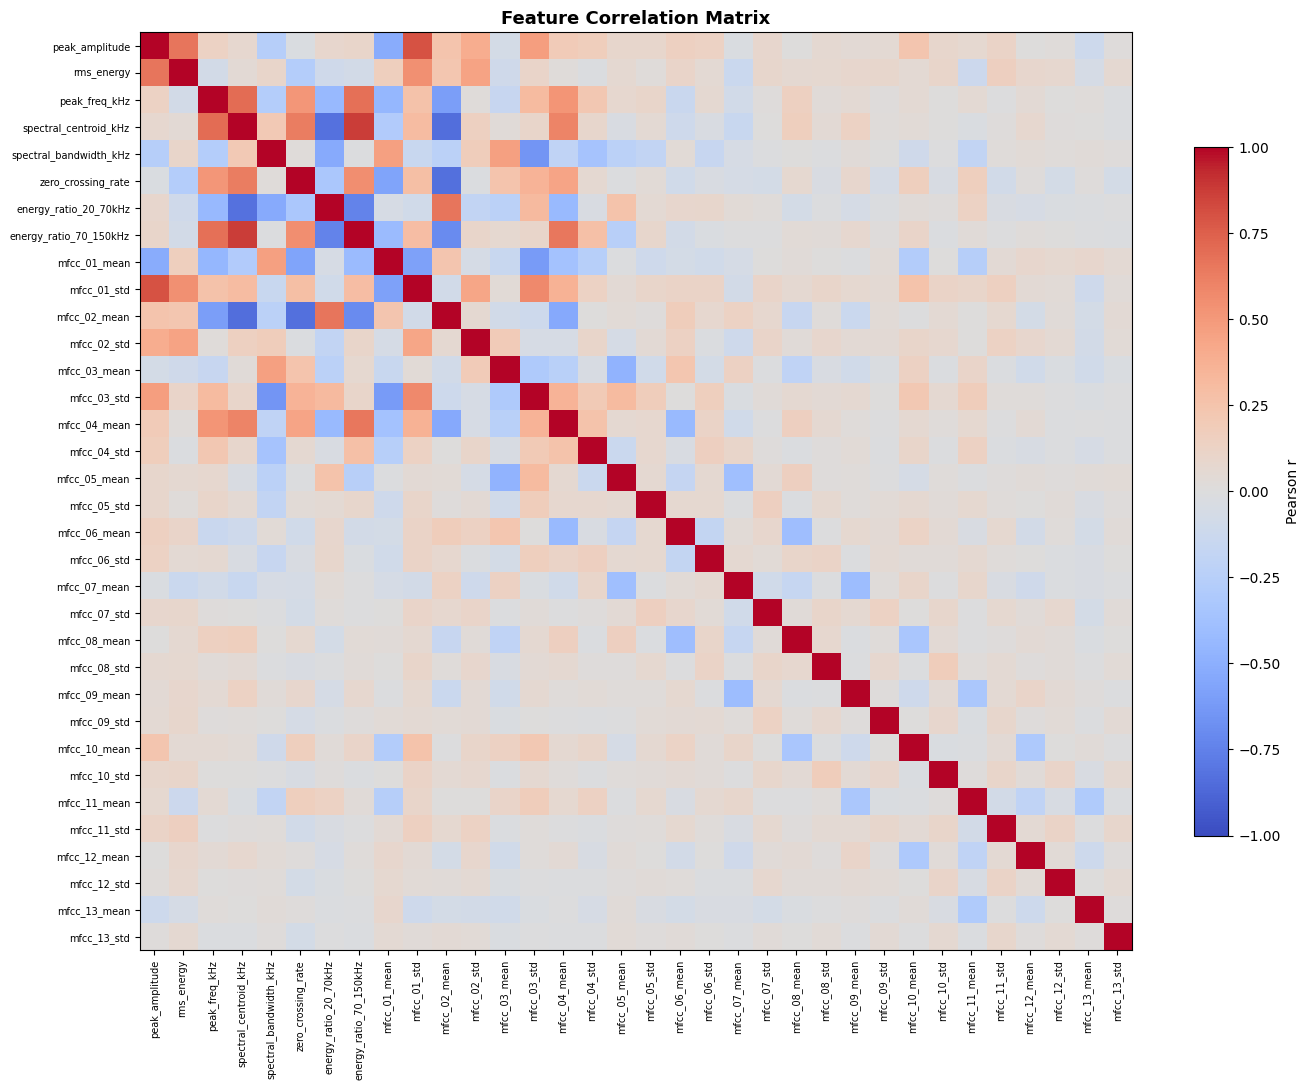

Saved: features_correlation.png

Top 10 most correlated feature pairs:
spectral_centroid_kHz   energy_ratio_70_150kHz    0.871
                        mfcc_02_mean              0.842
zero_crossing_rate      mfcc_02_mean              0.828
spectral_centroid_kHz   energy_ratio_20_70kHz     0.827
peak_amplitude          mfcc_01_std               0.802
energy_ratio_20_70kHz   energy_ratio_70_150kHz    0.736
energy_ratio_70_150kHz  mfcc_02_mean              0.699
peak_freq_kHz           spectral_centroid_kHz     0.696
                        energy_ratio_70_150kHz    0.681
energy_ratio_20_70kHz   mfcc_02_mean              0.661


In [39]:
# ── 5b-2. Correlation heatmap (pure matplotlib) ─────────────────────────────
corr = feat_df[feature_cols].corr().values
feat_labels = feature_cols
n = len(feat_labels)

fig, ax = plt.subplots(figsize=(14, 11))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
plt.colorbar(im, ax=ax, shrink=0.75, label="Pearson r")

ax.set_xticks(range(n))
ax.set_yticks(range(n))
ax.set_xticklabels(feat_labels, rotation=90, fontsize=7)
ax.set_yticklabels(feat_labels, fontsize=7)
ax.set_title("Feature Correlation Matrix", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("features_correlation.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: features_correlation.png")

# Top correlated pairs
corr_df = feat_df[feature_cols].corr()
corr_pairs = (
    corr_df.where(np.triu(np.ones(corr_df.shape), k=1).astype(bool))
            .stack()
            .abs()
            .sort_values(ascending=False)
)
print("\nTop 10 most correlated feature pairs:")
print(corr_pairs.head(10).round(3).to_string())


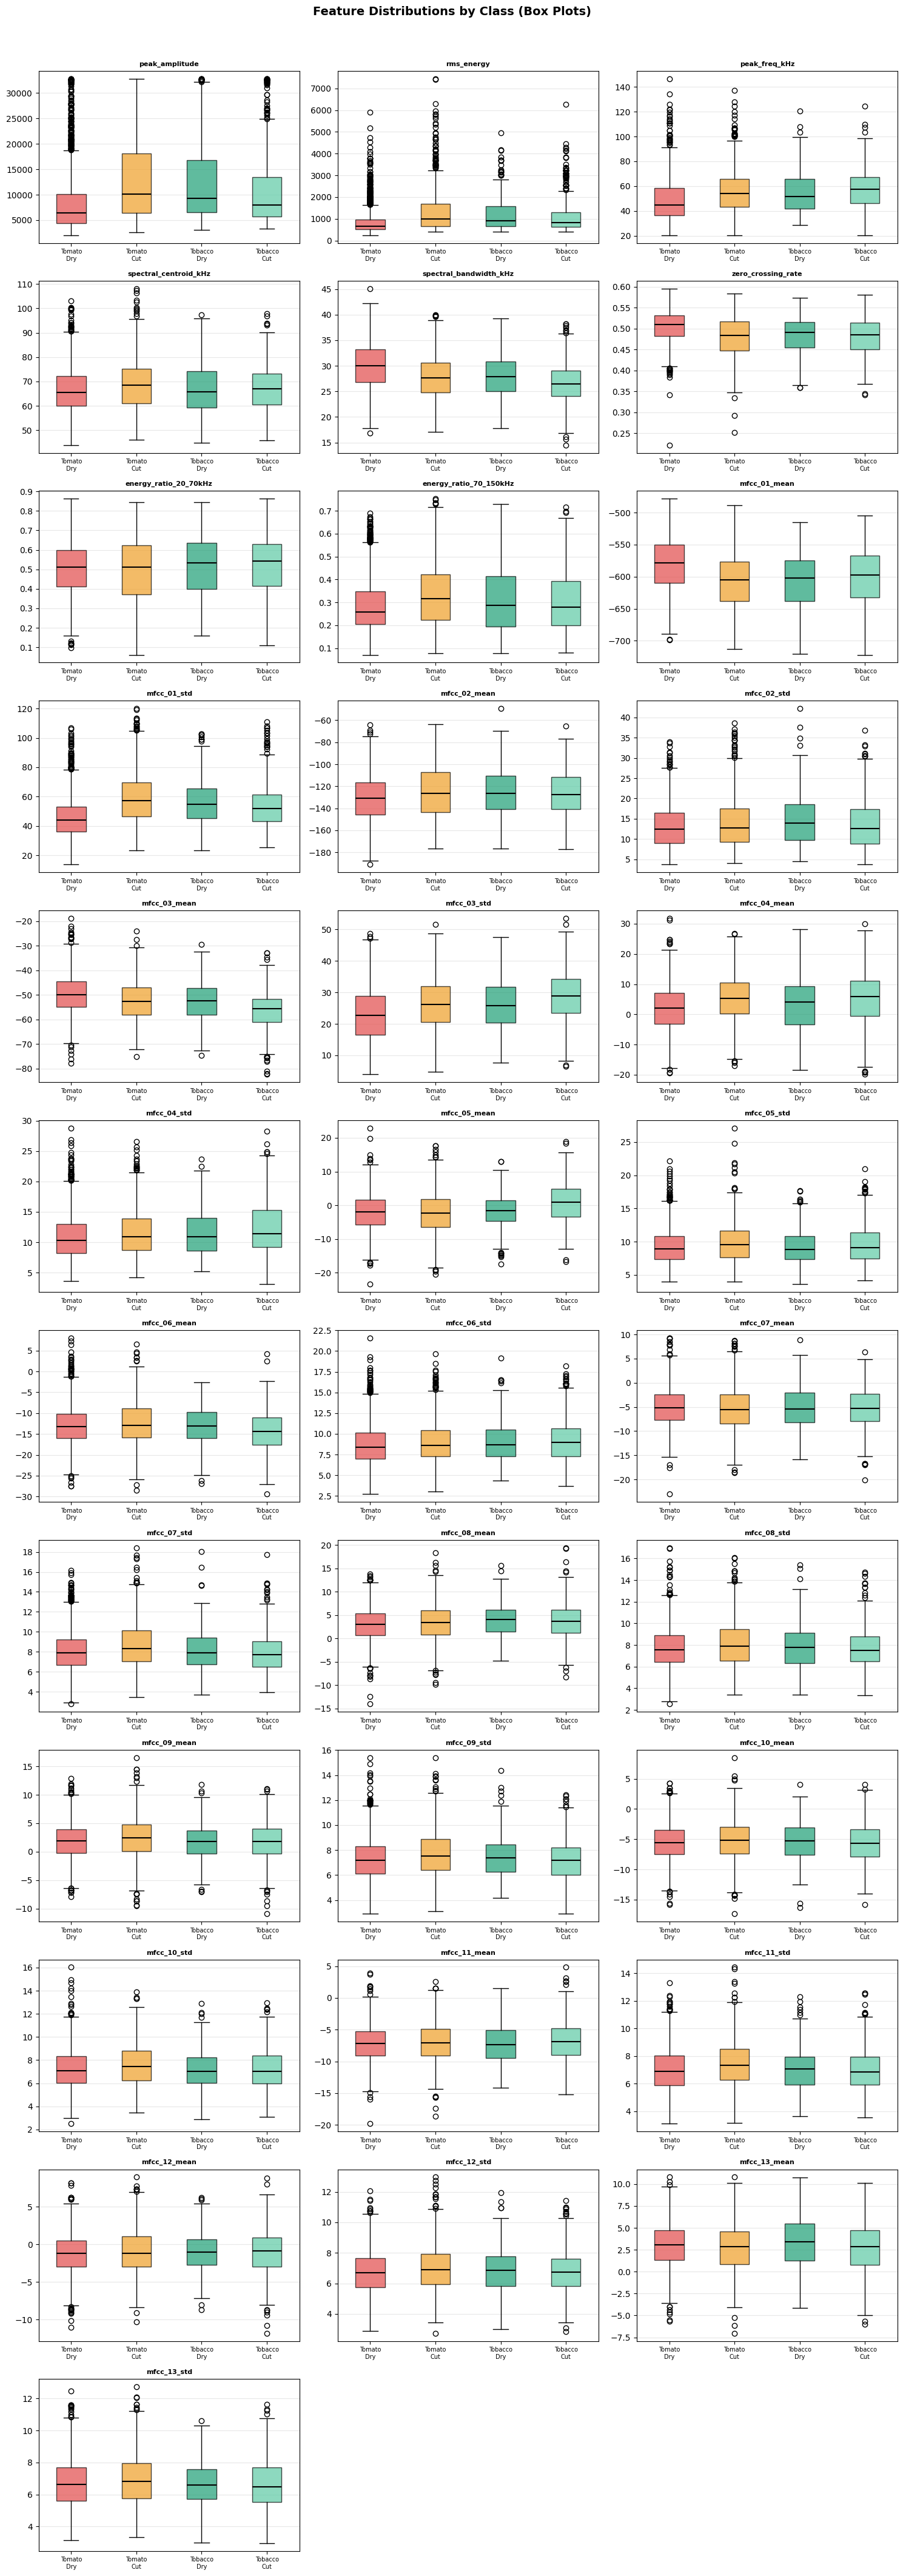

Saved: features_boxplots.png


In [40]:
# ── 5b-3. Box plots — all features by class ──────────────────────────────────
meta_cols = ["class", "plant_id", "sound_id", "filename"]

# Guard: needs feat_df with class column and feature_cols defined
if feat_df.empty or "class" not in feat_df.columns:
    print("⚠️  feat_df is empty or missing 'class' column.")
    print("   Run Section 4 (feature extraction) and Section 5 (sanity check) first.")
else:
    feat_cols_local = [c for c in feat_df.columns if c not in meta_cols]
    n_features = len(feat_cols_local)
    n_cols = 3
    n_rows = max(1, (n_features + n_cols - 1) // n_cols)

    palette = {
        "Tomato_Dry":  "#E24B4A",
        "Tomato_Cut":  "#EF9F27",
        "Tobacco_Dry": "#1D9E75",
        "Tobacco_Cut": "#5DCAA5",
    }
    # Keep only classes present in the data
    present_classes = [c for c in palette if c in feat_df["class"].unique()]
    present_colors  = [palette[c] for c in present_classes]

    fig, axes = plt.subplots(n_rows, n_cols,
                              figsize=(5 * n_cols, 3.5 * n_rows),
                              squeeze=False)   # always 2-D array
    fig.suptitle("Feature Distributions by Class (Box Plots)",
                 fontsize=14, fontweight="bold", y=1.01)

    for idx, feat in enumerate(feat_cols_local):
        ax = axes.flat[idx]
        data_by_class = [
            feat_df[feat_df["class"] == cls][feat].dropna().values
            for cls in present_classes
        ]
        bp = ax.boxplot(data_by_class, patch_artist=True,
                        medianprops=dict(color="black", linewidth=1.5))
        for patch, color in zip(bp["boxes"], present_colors):
            patch.set_facecolor(color)
            patch.set_alpha(0.7)
        ax.set_xticks(range(1, len(present_classes) + 1))
        ax.set_xticklabels([c.replace("_", "\n") for c in present_classes], fontsize=7)
        ax.set_title(feat, fontsize=8, fontweight="bold")
        ax.grid(axis="y", alpha=0.3)

    # Hide unused subplots
    for idx in range(n_features, n_rows * n_cols):
        axes.flat[idx].set_visible(False)

    plt.tight_layout()
    plt.savefig("features_boxplots.png", dpi=150, bbox_inches="tight")
    plt.show()
    print("Saved: features_boxplots.png")


## 6. Key feature distributions — peak frequency comparison

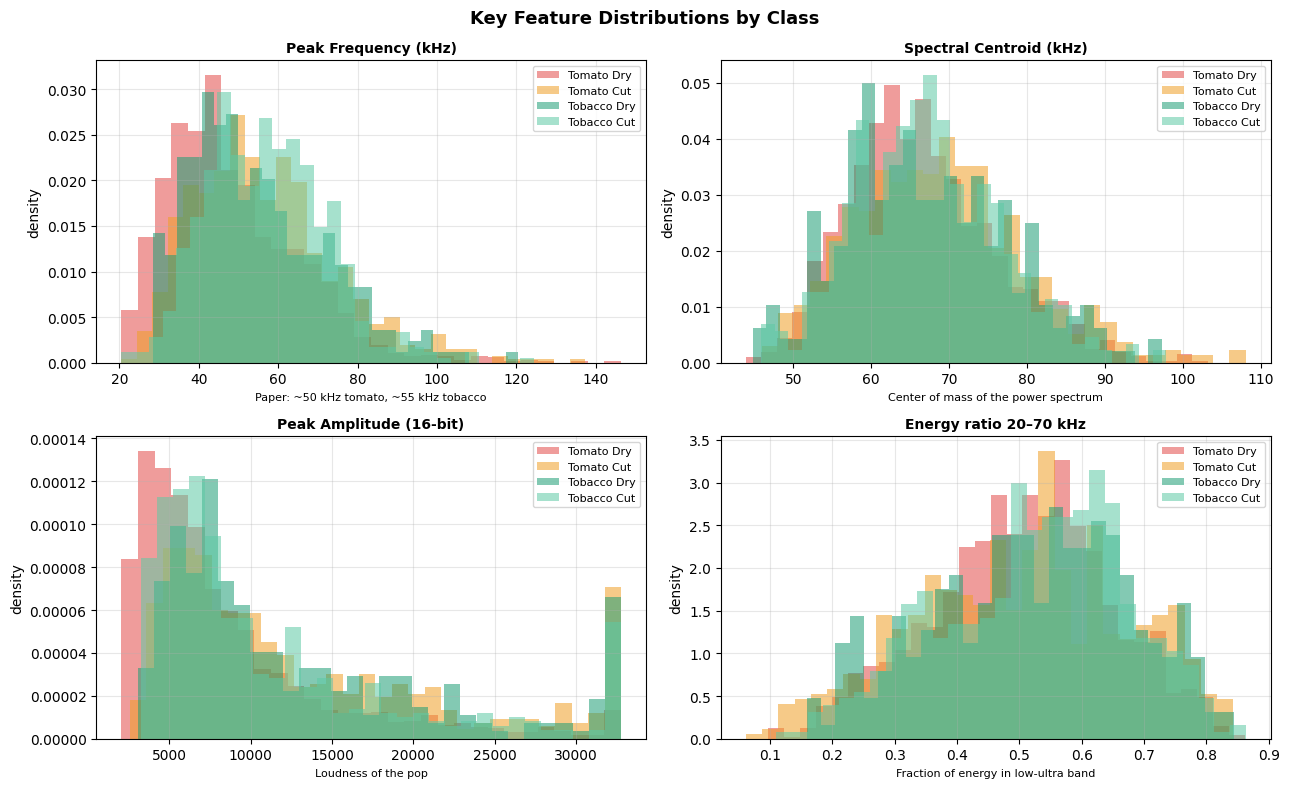

Saved: features_distributions.png


In [41]:
plant_classes = ["Tomato_Dry", "Tomato_Cut", "Tobacco_Dry", "Tobacco_Cut"]
colors        = ["#E24B4A", "#EF9F27", "#1D9E75", "#5DCAA5"]

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
fig.suptitle("Key Feature Distributions by Class",
             fontsize=13, fontweight="bold")

key_features = [
    ("peak_freq_kHz",           "Peak Frequency (kHz)",       "Paper: ~50 kHz tomato, ~55 kHz tobacco"),
    ("spectral_centroid_kHz",   "Spectral Centroid (kHz)",    "Center of mass of the power spectrum"),
    ("peak_amplitude",          "Peak Amplitude (16-bit)",    "Loudness of the pop"),
    ("energy_ratio_20_70kHz",   "Energy ratio 20–70 kHz",     "Fraction of energy in low-ultra band"),
]

for ax, (feat, title, subtitle) in zip(axes.flat, key_features):
    for cls, color in zip(plant_classes, colors):
        subset = feat_df[feat_df["class"] == cls][feat].dropna()
        if len(subset) == 0:
            continue
        ax.hist(subset, bins=30, color=color, alpha=0.55,
                label=cls.replace("_", " "), density=True)
    ax.set_title(title, fontsize=10, fontweight="bold")
    ax.set_xlabel(subtitle, fontsize=8)
    ax.set_ylabel("density")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("features_distributions.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: features_distributions.png")

## 7. Spectrogram gallery — visual check of feature extraction quality

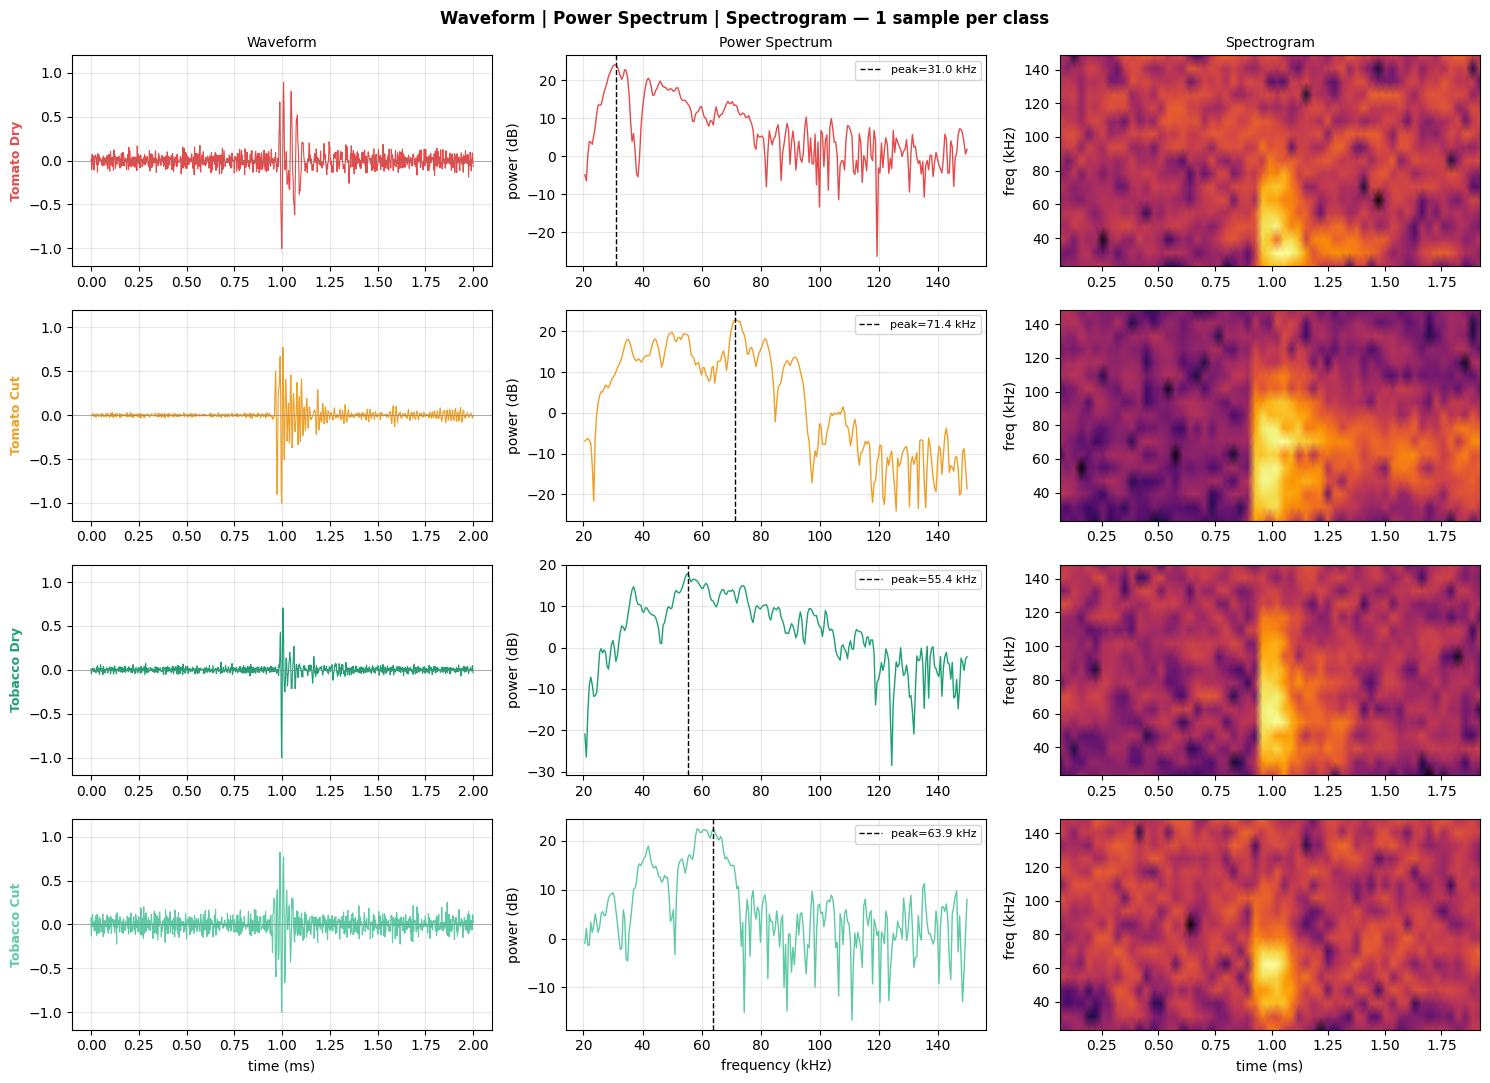

Saved: features_signal_gallery.png


In [42]:
np.random.seed(42)
show_classes = ["Tomato_Dry", "Tomato_Cut", "Tobacco_Dry", "Tobacco_Cut"]
show_colors  = ["#E24B4A", "#EF9F27", "#1D9E75", "#5DCAA5"]

fig, axes = plt.subplots(4, 3, figsize=(15, 11))
fig.suptitle("Waveform | Power Spectrum | Spectrogram — 1 sample per class",
             fontsize=12, fontweight="bold")

for row_idx, (cls, color) in enumerate(zip(show_classes, show_colors)):
    subset = feat_df[feat_df["class"] == cls]
    if len(subset) == 0:
        continue
    sample_row = subset.sample(1).iloc[0]
    fpath = DATA_ROOT / CLASS_FOLDERS[cls] / sample_row["filename"]

    if not fpath.exists():
        continue

    signal   = load_wav(str(fpath))
    sig_norm = signal / (np.max(np.abs(signal)) + 1e-9)
    t        = np.arange(len(signal)) / SR * 1000  # ms

    # Waveform
    ax = axes[row_idx][0]
    ax.plot(t, sig_norm, color=color, linewidth=0.8)
    ax.axhline(0, color="gray", linewidth=0.4)
    ax.set_ylabel(cls.replace("_", " "), color=color, fontweight="bold", fontsize=9)
    ax.set_xlabel("time (ms)" if row_idx == 3 else "")
    if row_idx == 0: ax.set_title("Waveform", fontsize=10)
    ax.set_ylim([-1.2, 1.2]); ax.grid(alpha=0.3)

    # Power spectrum
    ax2 = axes[row_idx][1]
    fft_mag = np.abs(rfft(sig_norm * np.hanning(len(sig_norm))))
    freqs   = rfftfreq(len(sig_norm), 1/SR) / 1000  # kHz
    mask    = (freqs >= 20) & (freqs <= 150)
    ax2.plot(freqs[mask], 20*np.log10(fft_mag[mask] + 1e-10), color=color, linewidth=1)
    peak_f  = sample_row["peak_freq_kHz"]
    ax2.axvline(peak_f, color="black", linestyle="--", linewidth=1,
                label=f"peak={peak_f:.1f} kHz")
    ax2.set_xlabel("frequency (kHz)" if row_idx == 3 else "")
    ax2.set_ylabel("power (dB)")
    ax2.legend(fontsize=8)
    if row_idx == 0: ax2.set_title("Power Spectrum", fontsize=10)
    ax2.grid(alpha=0.3)

    # Spectrogram
    ax3 = axes[row_idx][2]
    f_sg, t_sg, Sxx = scipy_spectrogram(signal, fs=SR,
                                         nperseg=64, noverlap=48)
    Sxx_db = 10 * np.log10(Sxx + 1e-10)
    f_mask = (f_sg >= 20_000) & (f_sg <= 150_000)
    ax3.pcolormesh(t_sg*1000, f_sg[f_mask]/1000, Sxx_db[f_mask],
                   cmap="inferno", shading="gouraud")
    ax3.set_xlabel("time (ms)" if row_idx == 3 else "")
    ax3.set_ylabel("freq (kHz)")
    if row_idx == 0: ax3.set_title("Spectrogram", fontsize=10)

plt.tight_layout()
plt.savefig("features_signal_gallery.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: features_signal_gallery.png")

## 8. Save feature matrix

In [43]:
output_path = "bioacoustics_features.csv"
feat_df.to_csv(output_path, index=False)

print(f"Feature matrix saved to: {output_path}")
print(f"Shape                  : {feat_df.shape}")
print(f"Feature columns        : {len(feature_cols)}")
print(f"Meta columns           : class, plant_id, sound_id, filename")

print("\n=== FEATURE EXTRACTION SUMMARY ===")
print(feat_df.groupby("class")[feature_cols[:3]].mean().round(2).to_string())

print("\nPeak frequency by class (should match paper's 49.6 kHz for Tomato_Dry):")
pf = feat_df.groupby("class")["peak_freq_kHz"].agg(["mean", "std"])
pf.columns = ["mean_kHz", "std_kHz"]
print(pf.round(2).to_string())

print("\nFeature extraction complete. Proceed to NB_BioAcoustics_3_Classification.ipynb")

Feature matrix saved to: bioacoustics_features.csv
Shape                  : (5477, 38)
Feature columns        : 34
Meta columns           : class, plant_id, sound_id, filename

=== FEATURE EXTRACTION SUMMARY ===
                  peak_amplitude  rms_energy  peak_freq_kHz
class                                                      
Empty_Pot               12186.15     1118.39          54.12
Greenhouse_Noise        10217.40     2857.10          34.14
Tobacco_Cut             11044.19     1114.26          57.38
Tobacco_Dry             12718.92     1218.85          54.90
Tomato_Cut              13220.47     1395.61          56.72
Tomato_Dry               8484.84      863.84          48.70

Peak frequency by class (should match paper's 49.6 kHz for Tomato_Dry):
                  mean_kHz  std_kHz
class                              
Empty_Pot            54.12    16.22
Greenhouse_Noise     34.14    12.38
Tobacco_Cut          57.38    14.98
Tobacco_Dry          54.90    17.05
Tomato_Cut         